# QTL recording quality control

This notebook is the dedicated home for general trajectory and video-recording quality control in the QTL workflow. Its goal is to identify complete experiments that may need review because of recording, tracking, or trajectory-data problems, rather than to identify biologically unusual individual fish. It is intentionally separate from `QTLQualityControl.ipynb`, which focuses on fish-level behavioral and measurement QC.

The current analysis was migrated from Section 11 of `QTLQualityControl.ipynb`. It reads every requested trajectory frame and reports missing positions, positions outside the expected dish, and implausibly large frame-to-frame jumps. These diagnostics are currently calculated per fish so that the source and extent of a recording problem remain visible; future recording-level checks can aggregate this evidence to flag whole experiments and add video-specific diagnostics. The flags are advisory and do not remove experiments or fish from downstream analyses.

This notebook loads its own QTL summaries, trajectory selections, and plot settings. It reuses the cohort and time-window defaults from `QTLQualityControl.ipynb`, while its diagnostics and SI overlays focus on technical video and tracking quality.

# QTL recording quality control setup

This notebook loads the QTL experiment and fish summaries using the same cohort and time-window settings as `QTLQualityControl.ipynb`. It then calculates full-frame recording and tracking diagnostics independently of fish-level behavioral QC.

In [1]:
from pathlib import Path
import glob
import hashlib
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Locate the repository whether launched from the repository root, Analyses,
# or Analyses/QTLmapping.
REPO_DIR = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'models').is_dir() and (candidate / 'functions').is_dir():
        REPO_DIR = candidate.resolve()
        break
if REPO_DIR is None:
    raise FileNotFoundError(
        'Could not locate the jlsocialbehavior repository from the current directory.'
    )
os.chdir(REPO_DIR)

from functions.technical_trajectory_qc import (
    add_technical_qc_flags,
    collect_qtl_technical_qc,
    plot_si_with_technical_flags,
    plot_technical_qc_distributions,
)

PROCESSING_SETTINGS_CSV = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/'
    'temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv'
)
META_FILE = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/'
    'Carlos/Behavior/QTL/MetaData_QTL.xlsx'
)
PROCESSING_DIR = str(Path(PROCESSING_SETTINGS_CSV).parent)
OUTPUT_DIR = (
    '//nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/'
    'temp/shoaling_selection/ShoalQTL_temp_output/qtl_quality_control'
)

# Keep the cohort and time selection aligned with QTLQualityControl.
EXPERIMENT_START_DATE = '2026-06-01'
EXPERIMENT_END_DATE = None
QC_WINDOW_METHOD = 'continuous'
CONTINUOUS_WINDOW_MIN = (60, 120)
EPISODE_WINDOW_MIN = (80, 240)
QC_EPISODE = '02k20f'
QC_GENOTYPE = 'F2'
EXPECTED_N_FISH = 35
FPS = 30
EPISODE_DURATION_MIN = 5

SAVE_OUTPUTS = True
USE_TECHNICAL_QC_CACHE = True
FIGURE_DPI = 180
FINAL_SI_PLOT_HEIGHT = 10.0
FINAL_SI_Y_LIMITS = None
CACHE_DIR = str(Path(OUTPUT_DIR) / 'cache')
TECHNICAL_QC_CACHE_DIR = Path(CACHE_DIR) / 'technical_qc'
UNFLAGGED_COLOR = '#8C8C8C'
SUMMARY_COLOR = '#202020'

TECHNICAL_QC_FRACTION_THRESHOLD = 0.001
TECHNICAL_QC_MAX_JUMP_MM_PER_FRAME = 20.0
TECHNICAL_QC_METRICS = {
    'missing_position': {
        'column': 'missing_position_fraction',
        'label': 'Missing-position fraction',
        'color': '#B2182B',
        'marker': 'X',
        'marker_size': 150,
        'abbreviation': 'missing',
    },
    'outside_dish': {
        'column': 'outside_dish_fraction',
        'label': 'Outside-dish fraction',
        'color': '#EF8A62',
        'marker': 'P',
        'marker_size': 170,
        'abbreviation': 'outside',
    },
    'implausible_jump': {
        'column': 'implausible_jump_fraction',
        'label': 'Implausible-jump fraction',
        'color': '#762A83',
        'marker': '*',
        'marker_size': 205,
        'abbreviation': 'jump',
    },
}

def parse_optional_date(value, setting_name):
    if value is None:
        return None
    try:
        return pd.to_datetime(value, format='%Y-%m-%d', errors='raise').normalize()
    except (TypeError, ValueError) as exc:
        raise ValueError(f'{setting_name} must be None or a valid YYYY-MM-DD date.') from exc

def validate_minute_window(value, setting_name):
    if (
        not isinstance(value, (tuple, list))
        or len(value) != 2
        or not all(np.isfinite(value))
    ):
        raise ValueError(f'{setting_name} must contain two finite minute values.')
    start, stop = map(float, value)
    if start < 0 or stop <= start:
        raise ValueError(f'{setting_name} must satisfy 0 <= start < stop.')
    return start, stop

FILTER_START_DATE = parse_optional_date(EXPERIMENT_START_DATE, 'EXPERIMENT_START_DATE')
FILTER_END_DATE = parse_optional_date(EXPERIMENT_END_DATE, 'EXPERIMENT_END_DATE')
if FILTER_START_DATE is not None and FILTER_END_DATE is not None and FILTER_START_DATE > FILTER_END_DATE:
    raise ValueError('EXPERIMENT_START_DATE must not be later than EXPERIMENT_END_DATE.')
QC_WINDOW_METHOD = str(QC_WINDOW_METHOD).strip().casefold()
if QC_WINDOW_METHOD not in {'continuous', 'episode'}:
    raise ValueError("QC_WINDOW_METHOD must be either 'continuous' or 'episode'.")
CONTINUOUS_WINDOW_MIN = validate_minute_window(
    CONTINUOUS_WINDOW_MIN, 'CONTINUOUS_WINDOW_MIN'
)
EPISODE_WINDOW_MIN = validate_minute_window(EPISODE_WINDOW_MIN, 'EPISODE_WINDOW_MIN')
if EXPECTED_N_FISH < 1 or FPS <= 0 or EPISODE_DURATION_MIN <= 0:
    raise ValueError('Fish count, FPS, and episode duration must be positive.')
if not np.isfinite(TECHNICAL_QC_FRACTION_THRESHOLD) or not 0 <= TECHNICAL_QC_FRACTION_THRESHOLD <= 1:
    raise ValueError('TECHNICAL_QC_FRACTION_THRESHOLD must be from 0 to 1.')
if not np.isfinite(TECHNICAL_QC_MAX_JUMP_MM_PER_FRAME) or TECHNICAL_QC_MAX_JUMP_MM_PER_FRAME <= 0:
    raise ValueError('TECHNICAL_QC_MAX_JUMP_MM_PER_FRAME must be positive and finite.')

if SAVE_OUTPUTS:
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
if USE_TECHNICAL_QC_CACHE:
    TECHNICAL_QC_CACHE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='ticks', context='notebook')

print('Repository:', REPO_DIR)
print('Processing settings:', PROCESSING_SETTINGS_CSV)
print('Metadata:', META_FILE)
print('Date filter:', FILTER_START_DATE, 'through', FILTER_END_DATE)
print('Window method:', QC_WINDOW_METHOD)
print('Continuous window:', CONTINUOUS_WINDOW_MIN, 'minutes')
print('Episode window:', EPISODE_WINDOW_MIN, 'minutes')


Repository: C:\Users\crodri19\larschpostdoc_analyses\selection_shoaling\jlsocialbehavior
Processing settings: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/03_Common_Use/temp/shoaling_selection/ShoalQTL_temp_processing/processingSettings.csv
Metadata: //nasdcsr.unil.ch/RECHERCHE/FAC/FBM/CIG/jlarsch/default/D2c/07_Data/Carlos/Behavior/QTL/MetaData_QTL.xlsx
Date filter: 2026-06-01 00:00:00 through None
Window method: continuous
Continuous window: (60.0, 120.0) minutes
Episode window: (80.0, 240.0) minutes


## QTL sample and frame selection

The helper functions below retain the QTL QC notebook's summary validation, F2 sample aggregation, and matching raw-frame selection. Edit the cohort and window settings above to change both the SI context and technical-QC frame selection.

In [2]:
SUMMARY_METRIC_COLUMNS = ['avgSpeed', 'thigmoIndex', 'anSize', 'boutDur', 'si']
SUMMARY_REQUIRED_COLUMNS = set(SUMMARY_METRIC_COLUMNS + ['episode', 'epStart', 'inDishTime'])


def normalize_episode(value):
    """Match the episode cleanup used by the QTL mapping notebook."""
    return str(value).strip().replace('_', '')


def parse_animal_numbers(value):
    """Parse experiment rosters such as '101:135', '101 102', or '101,102'."""
    text = str(value).strip()
    if not text or text.lower() == 'nan':
        return np.array([], dtype=int)
    if ':' in text:
        start_id, stop_id = text.split(':', 1)
        return np.arange(int(float(start_id)), int(float(stop_id)) + 1, dtype=int)
    return np.asarray([int(float(item)) for item in re.split(r'[\s,]+', text) if item], dtype=int)


def animal_numbers_for_experiment(row):
    """Return the ordered AllAn.anNr roster represented by one experiment row."""
    for column in ('anIDAll', 'anNr'):
        if column in row.index and pd.notna(row[column]):
            animal_numbers = parse_animal_numbers(row[column])
            if animal_numbers.size:
                return animal_numbers
    raise ValueError(f'No animal IDs were found for experiment {row.get("folder", row.name)}.')


def find_summary_file(txt_path):
    """Require exactly one canonical five-minute summary for a trajectory file."""
    txt_stem = Path(str(txt_path)).stem
    pattern = os.path.join(PROCESSING_DIR, txt_stem + '*siSummary_epi5.0.csv')
    matches = sorted(glob.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Expected exactly one summary for {txt_stem}; found {len(matches)} using {pattern}'
        )
    return matches[0]


def prepare_animal_metadata(animal_metadata):
    """Validate and normalize the metadata columns used for QTL sample labels."""
    required = {'anNr', 'QTLID', 'line', 'genotype'}
    missing = required - set(animal_metadata.columns)
    if missing:
        raise ValueError('AllAn metadata is missing columns: ' + ', '.join(sorted(missing)))

    metadata = animal_metadata[['anNr', 'QTLID', 'line', 'genotype']].copy()
    metadata['anNr'] = pd.to_numeric(metadata['anNr'], errors='coerce')
    metadata['QTLID'] = metadata['QTLID'].astype('string').str.strip().replace('', pd.NA)
    metadata['genotype'] = metadata['genotype'].astype('string').str.strip()
    metadata['line'] = metadata['line'].astype('string').str.strip()

    if metadata['anNr'].isna().any():
        raise ValueError('AllAn contains missing or non-numeric anNr values.')
    metadata['anNr'] = metadata['anNr'].astype(int)
    duplicate_numbers = metadata.loc[metadata['anNr'].duplicated(keep=False), 'anNr'].unique()
    if duplicate_numbers.size:
        preview = ', '.join(map(str, duplicate_numbers[:10]))
        raise ValueError(f'AllAn contains duplicate anNr values: {preview}')

    # QTLID is the global identifier used by this F2 QC analysis. Validate it
    # only within F2 because non-F2 metadata rows legitimately reuse some IDs.
    f2_mask = metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
    f2_metadata = metadata.loc[f2_mask]
    if f2_metadata['QTLID'].isna().any():
        raise ValueError('AllAn contains F2 rows with missing QTLID values.')
    duplicate_qtlids = f2_metadata.loc[
        f2_metadata['QTLID'].duplicated(keep=False), 'QTLID'
    ].unique()
    if duplicate_qtlids.size:
        preview = ', '.join(map(str, duplicate_qtlids[:10]))
        raise ValueError(f'AllAn contains duplicate F2 QTLID values: {preview}')

    return metadata


def map_summary_animal_numbers(summary, experiment_row):
    """Map zero-based summary animalIndex values to the experiment's AllAn.anNr roster."""
    if 'animalIndex' not in summary.columns:
        raise ValueError('Summary is missing the required animalIndex column.')

    # animalIndex is experiment-local. Resolve it through the ordered roster;
    # the writer's animalID field is not assumed to be a global QTLID.
    animal_numbers = animal_numbers_for_experiment(experiment_row)
    local_index = pd.to_numeric(summary['animalIndex'], errors='coerce')
    valid = local_index.notna() & local_index.between(0, len(animal_numbers) - 1)
    mapped_numbers = pd.Series(np.nan, index=summary.index, dtype=float)
    mapped_numbers.loc[valid] = animal_numbers[local_index.loc[valid].astype(int)]

    if mapped_numbers.isna().any():
        raise ValueError('Some summary animalIndex values could not be mapped to AllAn.anNr.')
    return mapped_numbers.astype(int)


# Regression check: identical local indices in different experiments must map
# through their own rosters and therefore resolve to different global QTLIDs.
_synthetic_metadata = prepare_animal_metadata(pd.DataFrame({
    'anNr': [101, 102, 201, 202],
    'QTLID': ['Q1_A1', 'Q1_A2', 'Q2_A1', 'Q2_A2'],
    'line': ['line_a', 'line_a', 'line_b', 'line_b'],
    'genotype': ['F2', 'F2', 'F2', 'F2'],
}))
_synthetic_summary = pd.DataFrame({'animalIndex': [0, 1], 'animalID': [0, 1]})
_synthetic_qtlids = []
for _synthetic_roster in ('101:102', '201:202'):
    _synthetic_numbers = map_summary_animal_numbers(
        _synthetic_summary,
        pd.Series({'anNr': _synthetic_roster, 'folder': 'synthetic'}),
    )
    _synthetic_qtlids.append(
        _synthetic_metadata.set_index('anNr').loc[_synthetic_numbers, 'QTLID'].tolist()
    )
assert _synthetic_qtlids == [['Q1_A1', 'Q1_A2'], ['Q2_A1', 'Q2_A2']]


def select_experiment_rows(processing_settings):
    """Apply the inclusive, user-editable experiment date filter."""
    required = {'txtPath', 'date', 'folder'}
    missing = required - set(processing_settings.columns)
    if missing:
        raise ValueError('Processing settings are missing columns: ' + ', '.join(sorted(missing)))
    if processing_settings.index.duplicated().any():
        raise ValueError('Processing settings contain duplicate row indices.')

    selected = processing_settings.copy()
    selected['_experiment_date'] = pd.to_datetime(selected['date'], dayfirst=True, errors='coerce').dt.normalize()
    invalid_dates = selected['_experiment_date'].isna()
    if invalid_dates.any():
        preview = ', '.join(selected.loc[invalid_dates, 'date'].astype(str).unique()[:5])
        raise ValueError('Could not parse experiment dates: ' + preview)

    keep = pd.Series(True, index=selected.index)
    if FILTER_START_DATE is not None:
        keep &= selected['_experiment_date'] >= FILTER_START_DATE
    if FILTER_END_DATE is not None:
        keep &= selected['_experiment_date'] <= FILTER_END_DATE

    selected = selected.loc[keep].copy()
    if selected.empty:
        raise ValueError('No experiments remain after applying the date filter.')
    selected['experiment_key'] = selected.index.map(str)
    return selected


def select_qc_window_rows(
    summary,
    experiment_row,
    window_method,
    continuous_window,
    episode_window,
    qc_episode,
):
    """Select summary rows and matching raw-frame segments for one method."""
    block_duration_min = float(experiment_row.get('epiDur', EPISODE_DURATION_MIN))
    if not np.isfinite(block_duration_min) or block_duration_min <= 0:
        raise ValueError('epiDur must be a positive finite number of minutes.')
    block_frames = int(round(block_duration_min * 60 * FPS))

    # Each epStart must describe exactly one canonical block, even though the
    # summary repeats that block once per fish.
    block_columns = ['epStart', 'inDishTime', 'episode_clean']
    block_table = summary[block_columns].drop_duplicates().sort_values('epStart')
    if block_table['epStart'].duplicated().any():
        raise ValueError('One epStart has conflicting inDishTime or episode labels.')

    if window_method == 'continuous':
        window_start, window_stop = continuous_window
        start_frame_float = window_start * 60 * FPS
        stop_frame_float = window_stop * 60 * FPS
        start_frame = int(round(start_frame_float))
        stop_frame = int(round(stop_frame_float))
        if not np.isclose(start_frame_float, start_frame) or not np.isclose(
            stop_frame_float, stop_frame
        ):
            raise ValueError('Continuous-window boundaries must resolve to whole frames.')
        if start_frame % block_frames or stop_frame % block_frames:
            raise ValueError(
                'CONTINUOUS_WINDOW_MIN boundaries must align with canonical '
                f'{block_duration_min:g}-minute summary blocks.'
            )

        expected_starts = np.arange(start_frame, stop_frame, block_frames, dtype=int)
        available_starts = block_table['epStart'].astype(int).to_numpy()
        missing_starts = expected_starts[~np.isin(expected_starts, available_starts)]
        if missing_starts.size:
            preview = ', '.join(map(str, missing_starts[:6]))
            raise ValueError(
                'Continuous window is not completely tiled by summary blocks; '
                + 'missing epStart frame(s): '
                + preview
            )
        selected_rows = summary[summary['epStart'].isin(expected_starts)].copy()
        segments = ((start_frame, stop_frame),)
        selected_starts = expected_starts
        window_label = f'continuous_{window_start:g}-{window_stop:g}_raw_min'
    elif window_method == 'episode':
        window_start, window_stop = episode_window
        selected_rows = summary[
            summary['episode_clean'].eq(normalize_episode(qc_episode))
            & summary['inDishTime'].gt(window_start)
            & summary['inDishTime'].lt(window_stop)
        ].copy()
        selected_starts = np.sort(selected_rows['epStart'].dropna().astype(int).unique())
        segments = tuple(
            (int(start), int(start + block_frames)) for start in selected_starts
        )
        window_label = (
            f'episode_{normalize_episode(qc_episode)}_'
            f'{window_start:g}-{window_stop:g}_in_dish_min'
        )
    else:
        raise ValueError(f'Unknown QC window method: {window_method}')

    if selected_rows.empty or len(selected_starts) == 0:
        raise ValueError(f'No summary blocks were selected for {window_label}.')

    selection = {
        'window_method': window_method,
        'window_label': window_label,
        'segments': segments,
        'selected_summary_blocks': int(len(selected_starts)),
        'analyzed_duration_min': float(
            sum(stop - start for start, stop in segments) / (FPS * 60)
        ),
    }
    return selected_rows, selection


# Transparent selection checks use the same alternating five-minute schedule as
# the QTL summaries. The 60-90 minute test window selects six complete blocks.
_synthetic_starts = np.arange(24, dtype=int) * EPISODE_DURATION_MIN * 60 * FPS
_synthetic_window_summary = pd.DataFrame({
    'epStart': _synthetic_starts,
    'inDishTime': 10 + _synthetic_starts / (FPS * 60),
    'episode_clean': np.where(np.arange(24) % 2 == 0, '01k01f', '02k20f'),
})
_continuous_rows, _continuous_selection = select_qc_window_rows(
    _synthetic_window_summary,
    pd.Series({'epiDur': EPISODE_DURATION_MIN}),
    'continuous',
    (60, 90),
    (80, 240),
    '02k20f',
)
assert _continuous_selection['segments'] == ((108000, 162000),)
assert _continuous_selection['selected_summary_blocks'] == 6
assert set(_continuous_rows['episode_clean']) == {'01k01f', '02k20f'}
_episode_rows, _episode_selection = select_qc_window_rows(
    _synthetic_window_summary,
    pd.Series({'epiDur': EPISODE_DURATION_MIN}),
    'episode',
    (60, 90),
    (80, 240),
    '02k20f',
)
assert _episode_rows['episode_clean'].eq('02k20f').all()
try:
    select_qc_window_rows(
        _synthetic_window_summary,
        pd.Series({'epiDur': EPISODE_DURATION_MIN}),
        'continuous',
        (62, 88),
        (80, 240),
        '02k20f',
    )
except ValueError:
    pass
else:
    raise AssertionError('Partial summary-block boundaries must be rejected.')


def load_qtl_summary_samples(processing_settings, animal_metadata):
    """Load summaries and return per-fish samples plus shared frame selections."""
    metadata = prepare_animal_metadata(animal_metadata)
    selected_experiments = select_experiment_rows(processing_settings)
    summary_parts = []
    selection_parts = []
    errors = []

    for _, experiment_row in selected_experiments.iterrows():
        experiment_key = experiment_row['experiment_key']
        experiment_name = str(experiment_row['folder'])
        try:
            expected_numbers = animal_numbers_for_experiment(experiment_row)
            expected_f2 = metadata[
                metadata['anNr'].isin(expected_numbers)
                & metadata['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
            ]

            summary_path = find_summary_file(experiment_row['txtPath'])
            summary = pd.read_csv(summary_path, index_col=0)
            missing = SUMMARY_REQUIRED_COLUMNS - set(summary.columns)
            if missing:
                raise ValueError('Summary is missing columns: ' + ', '.join(sorted(missing)))

            summary['anNr'] = map_summary_animal_numbers(summary, experiment_row)
            summary['episode_clean'] = summary['episode'].map(normalize_episode)
            summary['inDishTime'] = pd.to_numeric(summary['inDishTime'], errors='coerce')
            summary['epStart'] = pd.to_numeric(summary['epStart'], errors='coerce')

            # The same selection object drives summary aggregation and raw
            # trajectory loading, which samples within the same requested time segments.
            selected_rows, selection = select_qc_window_rows(
                summary,
                experiment_row,
                QC_WINDOW_METHOD,
                CONTINUOUS_WINDOW_MIN,
                EPISODE_WINDOW_MIN,
                QC_EPISODE,
            )

            selected_rows = selected_rows.merge(
                metadata,
                on='anNr',
                how='left',
                validate='many_to_one',
            )
            selected_f2 = selected_rows[
                selected_rows['genotype'].str.casefold().eq(QC_GENOTYPE.casefold())
            ].copy()

            if expected_f2.shape[0] and selected_f2.empty:
                raise ValueError('No F2 rows remain after the metadata merge.')
            if selected_f2.duplicated(['anNr', 'epStart']).any():
                raise ValueError('Selected summary contains duplicate fish-block rows.')

            # Require every expected F2 fish to contribute every selected block.
            expected_block_count = selection['selected_summary_blocks']
            fish_block_counts = (
                selected_f2.groupby('anNr')['epStart']
                .nunique()
                .reindex(expected_f2['anNr'], fill_value=0)
            )
            incomplete_fish = fish_block_counts[fish_block_counts.ne(expected_block_count)]
            if not incomplete_fish.empty:
                preview = ', '.join(
                    f'{animal_number}: {count}/{expected_block_count}'
                    for animal_number, count in incomplete_fish.head(10).items()
                )
                raise ValueError('Incomplete selected summary coverage by anNr: ' + preview)

            for metric_column in SUMMARY_METRIC_COLUMNS:
                selected_f2[metric_column] = pd.to_numeric(
                    selected_f2[metric_column],
                    errors='coerce',
                )

            selected_f2['experiment_key'] = experiment_key
            selected_f2['experiment'] = experiment_name
            selected_f2['date'] = experiment_row['_experiment_date']
            setup_value = experiment_row.get('setup', np.nan)
            if pd.isna(setup_value):
                raise ValueError('Experiment setup is missing; it is required for plot labels.')
            setup_text = re.sub(r'^[sS]', '', str(setup_value).strip())
            if re.fullmatch(r'\d+\.0+', setup_text):
                setup_text = str(int(float(setup_text)))
            if not setup_text:
                raise ValueError('Experiment setup is empty; it is required for plot labels.')
            selected_f2['setup'] = setup_value
            selected_f2['lineSet'] = (
                selected_f2['line'].astype(str)
                + '_'
                + experiment_row['_experiment_date'].strftime('%d-%m-%Y')
            )
            selected_f2['experiment_label'] = (
                selected_f2['lineSet'] + '_s' + setup_text
            )

            group_columns = [
                'experiment_key',
                'experiment',
                'date',
                'line',
                'lineSet',
                'experiment_label',
                'setup',
                'anNr',
                'QTLID',
                'genotype',
            ]
            per_fish = (
                selected_f2.groupby(group_columns, dropna=False, sort=True)[SUMMARY_METRIC_COLUMNS]
                .mean()
                .reset_index()
            )
            summary_parts.append(per_fish)

            selection_parts.append({
                'experiment_key': experiment_key,
                'experiment': experiment_name,
                **selection,
            })
        except Exception as exc:
            errors.append(f'{experiment_name}: {exc}')

    if errors:
        raise RuntimeError(
            'Summary loading was incomplete; fix these experiments before calculating recording QC:\n- '
            + '\n- '.join(errors)
        )
    if not summary_parts:
        raise ValueError('No F2 summary samples were loaded.')

    samples = pd.concat(summary_parts, ignore_index=True)
    trajectory_selections = pd.DataFrame(selection_parts)

    if samples.duplicated(['experiment_key', 'QTLID']).any():
        raise AssertionError('Per-fish aggregation did not produce unique experiment-animal rows.')

    # lineSet plus setup is concise but still distinguishes recordings made
    # from the same line on the same date. Require one unique label per experiment.
    experiment_labels = samples[
        ['experiment_key', 'experiment_label']
    ].drop_duplicates()
    if experiment_labels['experiment_key'].duplicated().any():
        raise ValueError('One experiment produced more than one lineSet/setup label.')
    if experiment_labels['experiment_label'].duplicated().any():
        duplicates = experiment_labels.loc[
            experiment_labels['experiment_label'].duplicated(keep=False),
            'experiment_label',
        ].unique()
        raise ValueError('lineSet/setup labels are not unique: ' + ', '.join(duplicates))

    if trajectory_selections['experiment_key'].duplicated().any():
        raise AssertionError('Trajectory selections are not unique by experiment.')

    return samples, trajectory_selections, selected_experiments, metadata

In [3]:
processing_settings = pd.read_csv(PROCESSING_SETTINGS_CSV, index_col=0)
animal_metadata_raw = pd.read_excel(META_FILE, sheet_name='AllAn')

summary_samples, trajectory_selections, selected_experiments, animal_metadata = (
    load_qtl_summary_samples(processing_settings, animal_metadata_raw)
)

print('Selected experiments:', selected_experiments.shape[0])
print('Loaded F2 experiment-animal samples:', summary_samples.shape[0])
print('Active time-selection method:', QC_WINDOW_METHOD)
display(
    trajectory_selections[
        [
            'experiment',
            'window_method',
            'window_label',
            'selected_summary_blocks',
            'analyzed_duration_min',
        ]
    ]
)
display(
    summary_samples[
        ['experiment_label', 'QTLID', 'anNr', 'genotype', 'si']
    ].head()
)


Selected experiments: 33
Loaded F2 experiment-animal samples: 1120
Active time-selection method: continuous


,experiment,window_method,window_label,selected_summary_blocks,analyzed_duration_min
0,20260626_q9_Sel1A_s2,continuous,continuous_60-120_raw_min,12,60.0
1,20260731_q10_Sel3A_s1,continuous,continuous_60-120_raw_min,12,60.0
2,20260731_q11_Sel3A_s2,continuous,continuous_60-120_raw_min,12,60.0
3,20260806_q12_Sel3C_s1,continuous,continuous_60-120_raw_min,12,60.0
4,20260806_q13_Sel3C_s2,continuous,continuous_60-120_raw_min,12,60.0
5,20260807_q14_Sel1B_s1,continuous,continuous_60-120_raw_min,12,60.0
6,20260807_q15_Sel1B_s2,continuous,continuous_60-120_raw_min,12,60.0
7,20260814_q16_Sel3D_s1,continuous,continuous_60-120_raw_min,12,60.0
8,20260814_q17_Sel3D_s2,continuous,continuous_60-120_raw_min,12,60.0
9,20260821_q18_Sel1A_s1,continuous,continuous_60-120_raw_min,12,60.0


,experiment_label,QTLID,anNr,genotype,si
0,Sel1A_26-06-2026_s2,Q9_A1,281,F2,0.165691
1,Sel1A_26-06-2026_s2,Q9_A2,282,F2,0.070591
2,Sel1A_26-06-2026_s2,Q9_A3,283,F2,0.293177
3,Sel1A_26-06-2026_s2,Q9_A4,284,F2,0.151945
4,Sel1A_26-06-2026_s2,Q9_A5,285,F2,0.037537


## Trajectory scale and figure helpers

These functions resolve the per-fish ROI scale used by technical trajectory QC and provide deterministic experiment plotting positions and figure saving.

In [4]:
def resolve_trajectory_scale(experiment_row, n_fish):
    """Return crop centres, shared pixels/mm, expected dish radius, and ROI path."""
    txt_path = str(experiment_row['txtPath'])
    start_dir = os.path.dirname(txt_path)
    dish_diameter_mm = float(experiment_row.get('dishDiameter_mm', 70))

    roi_matches = sorted(
        path for path in glob.glob(os.path.join(start_dir, 'ROIdef*'))
        if os.path.isfile(path)
    )
    if roi_matches:
        roi_path = roi_matches[0]
        try:
            rois = np.atleast_2d(np.loadtxt(roi_path))
        except Exception:
            rois = np.atleast_2d(np.loadtxt(roi_path, delimiter=','))
        if rois.shape[0] < n_fish:
            raise ValueError(f'ROI file has {rois.shape[0]} rows but {n_fish} fish are expected.')
        radii_px = rois[:n_fish, -1].astype(float)
        px_per_mm = 2 * np.nanmean(radii_px) / dish_diameter_mm
        centres_px = radii_px + 2
        return centres_px, px_per_mm, dish_diameter_mm / 2, roi_path

    raise FileNotFoundError(
        f'No ROIdef* file found in {start_dir or "."} for trajectory {txt_path}. '
        'An ROI file is required when loading raw trajectories without a matching enabled cache.'
    )

def experiment_plot_order(data):
    """Order experiment labels chronologically, retaining a stable secondary label sort."""
    return (
        data[['experiment_label', 'date']]
        .drop_duplicates()
        .sort_values(['date', 'experiment_label'])['experiment_label']
        .tolist()
    )


def stable_jitter_position(experiment_label, qtlid, experiment_order, width=0.16):
    """Create repeatable horizontal jitter from the experiment-animal identifier."""
    x_centre = experiment_order.index(experiment_label)
    token = f'{experiment_label}|{qtlid}'.encode('utf-8')
    integer = int(hashlib.sha1(token).hexdigest()[:8], 16)
    unit_value = integer / float(16 ** 8 - 1)
    return x_centre + (unit_value - 0.5) * 2 * width


def add_stable_plot_positions(data, experiment_order):
    """Attach deterministic x positions for QC annotation overlays."""
    positioned = data.copy()
    positioned['_plot_x'] = [
        stable_jitter_position(label, qtlid, experiment_order)
        for label, qtlid in zip(positioned['experiment_label'], positioned['QTLID'])
    ]
    return positioned


def save_figure(fig, stem):
    """Save both review-friendly PNG and vector PDF versions when enabled."""
    if not SAVE_OUTPUTS:
        return
    fig.savefig(Path(OUTPUT_DIR) / f'{stem}.png', dpi=FIGURE_DPI, bbox_inches='tight')
    fig.savefig(Path(OUTPUT_DIR) / f'{stem}.pdf', bbox_inches='tight')



## Full-frame technical trajectory QC

This analysis loads SI and sample identifiers for context, then calculates independent full-frame technical flags. It does not run the fish-level behavioral QC pipeline.

`QTLQualityControl.ipynb` separately computes `trajectory_invalid_sample_proportion` from stride-sampled frames. This notebook reads every requested frame and retains three technical reasons separately:

- `missing_position_fraction`: nonfinite x or y, including requested frames unavailable because sampling extends beyond the available trajectory-frame bounds.
- `outside_dish_fraction`: finite positions beyond the expected dish radius.
- `implausible_jump_fraction`: arrival frames displaced by more than the editable per-frame limit from the immediately preceding finite frame.

All fractions use requested full-resolution frames as their denominator. Technical flags use a strict greater-than comparison and remain independent of the existing fish-level QC flags.


In [5]:
technical_metric_results = collect_qtl_technical_qc(
    summary_sample_table=summary_samples,
    selections=trajectory_selections,
    experiments=selected_experiments,
    animal_numbers_for_experiment=animal_numbers_for_experiment,
    resolve_trajectory_scale=resolve_trajectory_scale,
    expected_n_fish=EXPECTED_N_FISH,
    fps=FPS,
    cache_dir=TECHNICAL_QC_CACHE_DIR,
    use_cache=USE_TECHNICAL_QC_CACHE,
    max_jump_mm_per_frame=TECHNICAL_QC_MAX_JUMP_MM_PER_FRAME,
)
technical_qc_table = add_technical_qc_flags(
    qc_table=summary_samples,
    technical_results=technical_metric_results,
    metric_definitions=TECHNICAL_QC_METRICS,
    threshold=TECHNICAL_QC_FRACTION_THRESHOLD,
)

# The fraction threshold is strict: equality is not flagged.
_technical_threshold_check = pd.Series([
    np.nextafter(TECHNICAL_QC_FRACTION_THRESHOLD, -np.inf),
    TECHNICAL_QC_FRACTION_THRESHOLD,
    np.nextafter(TECHNICAL_QC_FRACTION_THRESHOLD, np.inf),
    np.nan,
])
assert _technical_threshold_check.gt(
    TECHNICAL_QC_FRACTION_THRESHOLD
).fillna(False).tolist() == [False, False, True, False]

technical_fraction_columns = [
    metric_info['column'] for metric_info in TECHNICAL_QC_METRICS.values()
]
technical_flag_columns = [
    f'{metric_name}_technical_flag' for metric_name in TECHNICAL_QC_METRICS
]
technical_identity_columns = [
    'experiment_key',
    'experiment_label',
    'date',
    'QTLID',
    'anNr',
    'line',
    'genotype',
    'si',
]
technical_detail_columns = [
    'technical_requested_frames',
    'technical_observed_frames',
    'missing_position_count',
    'outside_dish_count',
    'implausible_jump_count',
    *technical_fraction_columns,
    *technical_flag_columns,
    'technical_qc_flag',
    'technical_qc_missing_flag',
    'technical_qc_reasons',
    'technical_cache_hit',
    'technical_cache_path',
    'technical_qc_error',
]
technical_metrics_export = technical_qc_table[
    technical_identity_columns + technical_detail_columns
].copy()
technical_flagged_fish = (
    technical_metrics_export.loc[technical_metrics_export['technical_qc_flag']]
    .sort_values(['date', 'experiment_label', 'QTLID'])
    .reset_index(drop=True)
)
technical_load_failures = (
    technical_metrics_export.loc[
        technical_metrics_export['technical_qc_error'].fillna('').ne(''),
        ['experiment_label', 'technical_qc_error'],
    ]
    .drop_duplicates()
    .sort_values('experiment_label')
    .reset_index(drop=True)
)

print('Technical-QC flagged experiment-fish samples:', len(technical_flagged_fish))
print('Experiments with technical-QC loading errors:', len(technical_load_failures))
display(technical_flagged_fish)
if not technical_load_failures.empty:
    display(technical_load_failures)

if SAVE_OUTPUTS:
    technical_metrics_export.to_csv(
        Path(OUTPUT_DIR) / 'qtl_technical_qc_metrics.csv',
        index=False,
    )
    technical_flagged_fish.to_csv(
        Path(OUTPUT_DIR) / 'qtl_technical_qc_flagged.csv',
        index=False,
    )


Technical-QC flagged experiment-fish samples: 11
Experiments with technical-QC loading errors: 0


,experiment_key,experiment_label,date,QTLID,anNr,line,genotype,si,technical_requested_frames,technical_observed_frames,...,implausible_jump_fraction,missing_position_technical_flag,outside_dish_technical_flag,implausible_jump_technical_flag,technical_qc_flag,technical_qc_missing_flag,technical_qc_reasons,technical_cache_hit,technical_cache_path,technical_qc_error
0,14,Sel1B_07-08-2026_s2,2026-08-07,Q15_E5,523,Sel1B,F2,3.382574e-02,108000,108000,...,0.000120,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
1,19,Sel1B_28-08-2026_s1,2026-08-28,Q20_D4,690,Sel1B,F2,4.534991e-02,108000,108000,...,0.000167,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
2,22,Sel3C_04-09-2026_s1,2026-09-04,Q23_C2,786,Sel3C,F2,1.461954e-01,108000,108000,...,0.000000,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
3,23,Sel3C_04-09-2026_s2,2026-09-04,Q24_C4,823,Sel3C,F2,4.164567e-02,108000,108000,...,0.000000,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
4,26,Sel1A_17-09-2026_s1,2026-09-17,Q27_D4,935,Sel1A,F2,-6.484397e-03,108000,108000,...,0.000102,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
5,26,Sel1A_17-09-2026_s1,2026-09-17,Q27_D5,936,Sel1A,F2,6.851333e-02,108000,108000,...,0.000074,False,True,False,True,False,Outside-dish fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
6,30,Sel3D_24-09-2026_s1,2026-09-24,Q31_A7,1057,Sel3D,F2,4.385979e-02,108000,108000,...,0.001472,False,False,True,True,False,Implausible-jump fraction > threshold,True,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
7,40,Sel1A_06-11-2026_s2,2026-11-06,Q41_A6,1406,Sel1A,F2,2.248133e-02,108000,108000,...,0.012102,False,True,True,True,False,Outside-dish fraction > threshold; Implausible...,False,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
8,40,Sel1A_06-11-2026_s2,2026-11-06,Q41_A7,1407,Sel1A,F2,1.723397e-03,108000,108000,...,0.000009,False,True,False,True,False,Outside-dish fraction > threshold,False,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,
9,40,Sel1A_06-11-2026_s2,2026-11-06,Q41_B6,1413,Sel1A,F2,1.137690e-01,108000,108000,...,0.001370,False,True,True,True,False,Outside-dish fraction > threshold; Implausible...,False,\\nasdcsr.unil.ch\RECHERCHE\FAC\FBM\CIG\jlarsc...,


### Technical-metric distributions and SI review

The distribution figure shows every fish, experiment medians and interquartile ranges, and the strict 0.001 cutoff. Its nonnegative symmetric-log axes retain exact zeros while expanding the region near the cutoff.

The second SI figure overlays the three independent technical flags only. Neither figure changes the samples contributing to SI summaries.


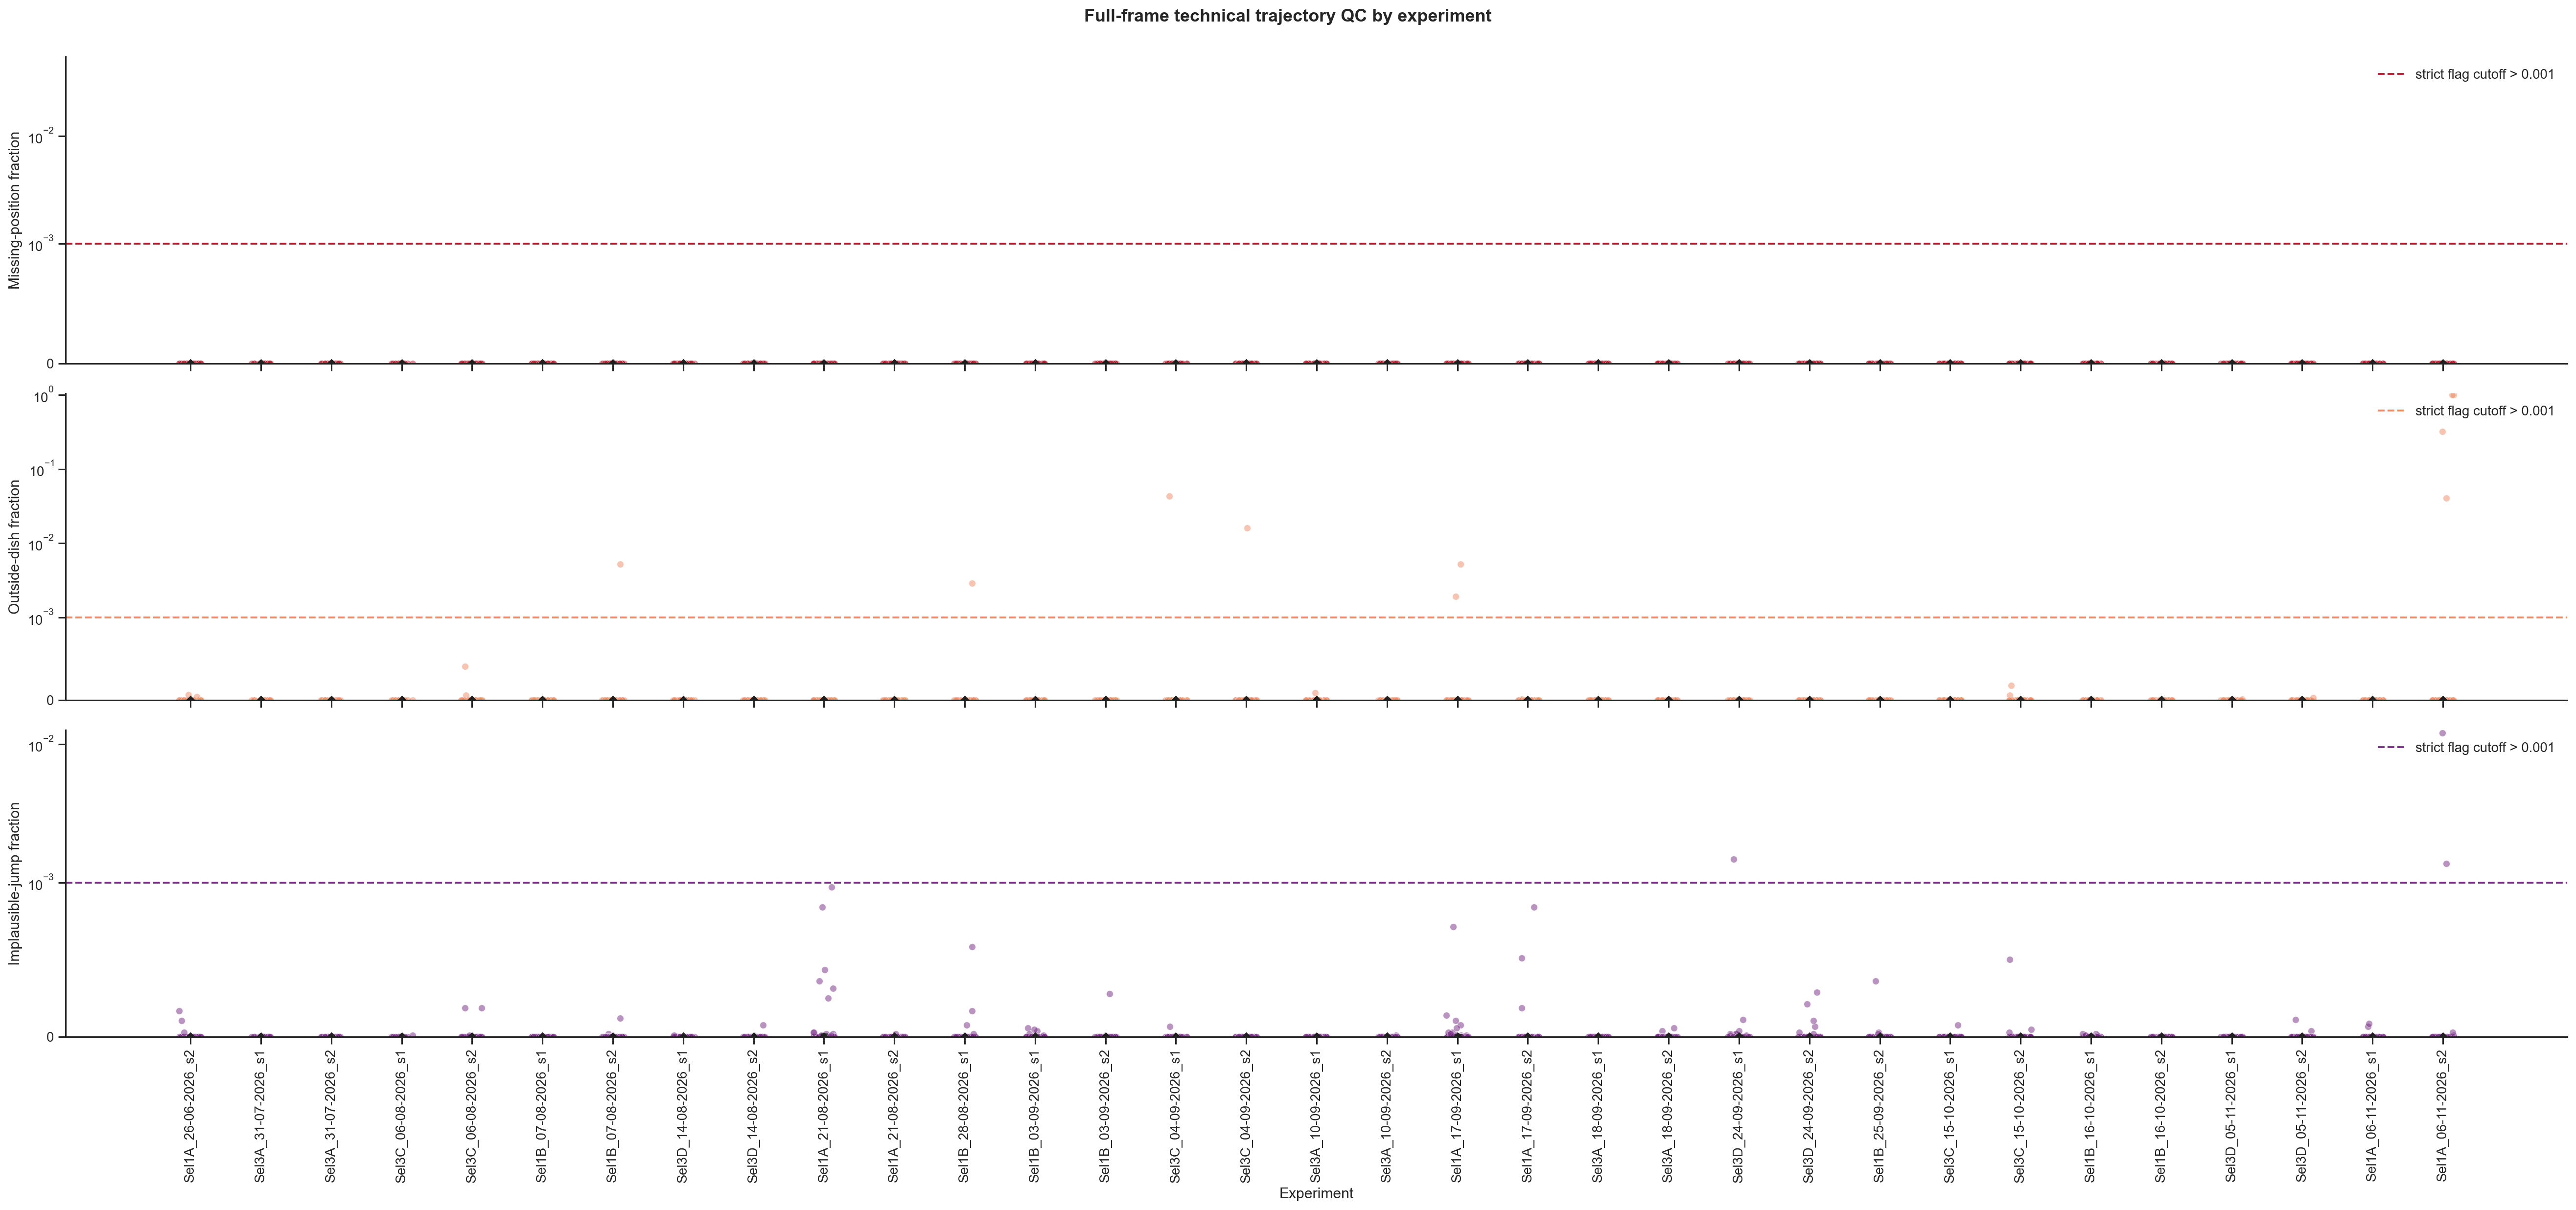

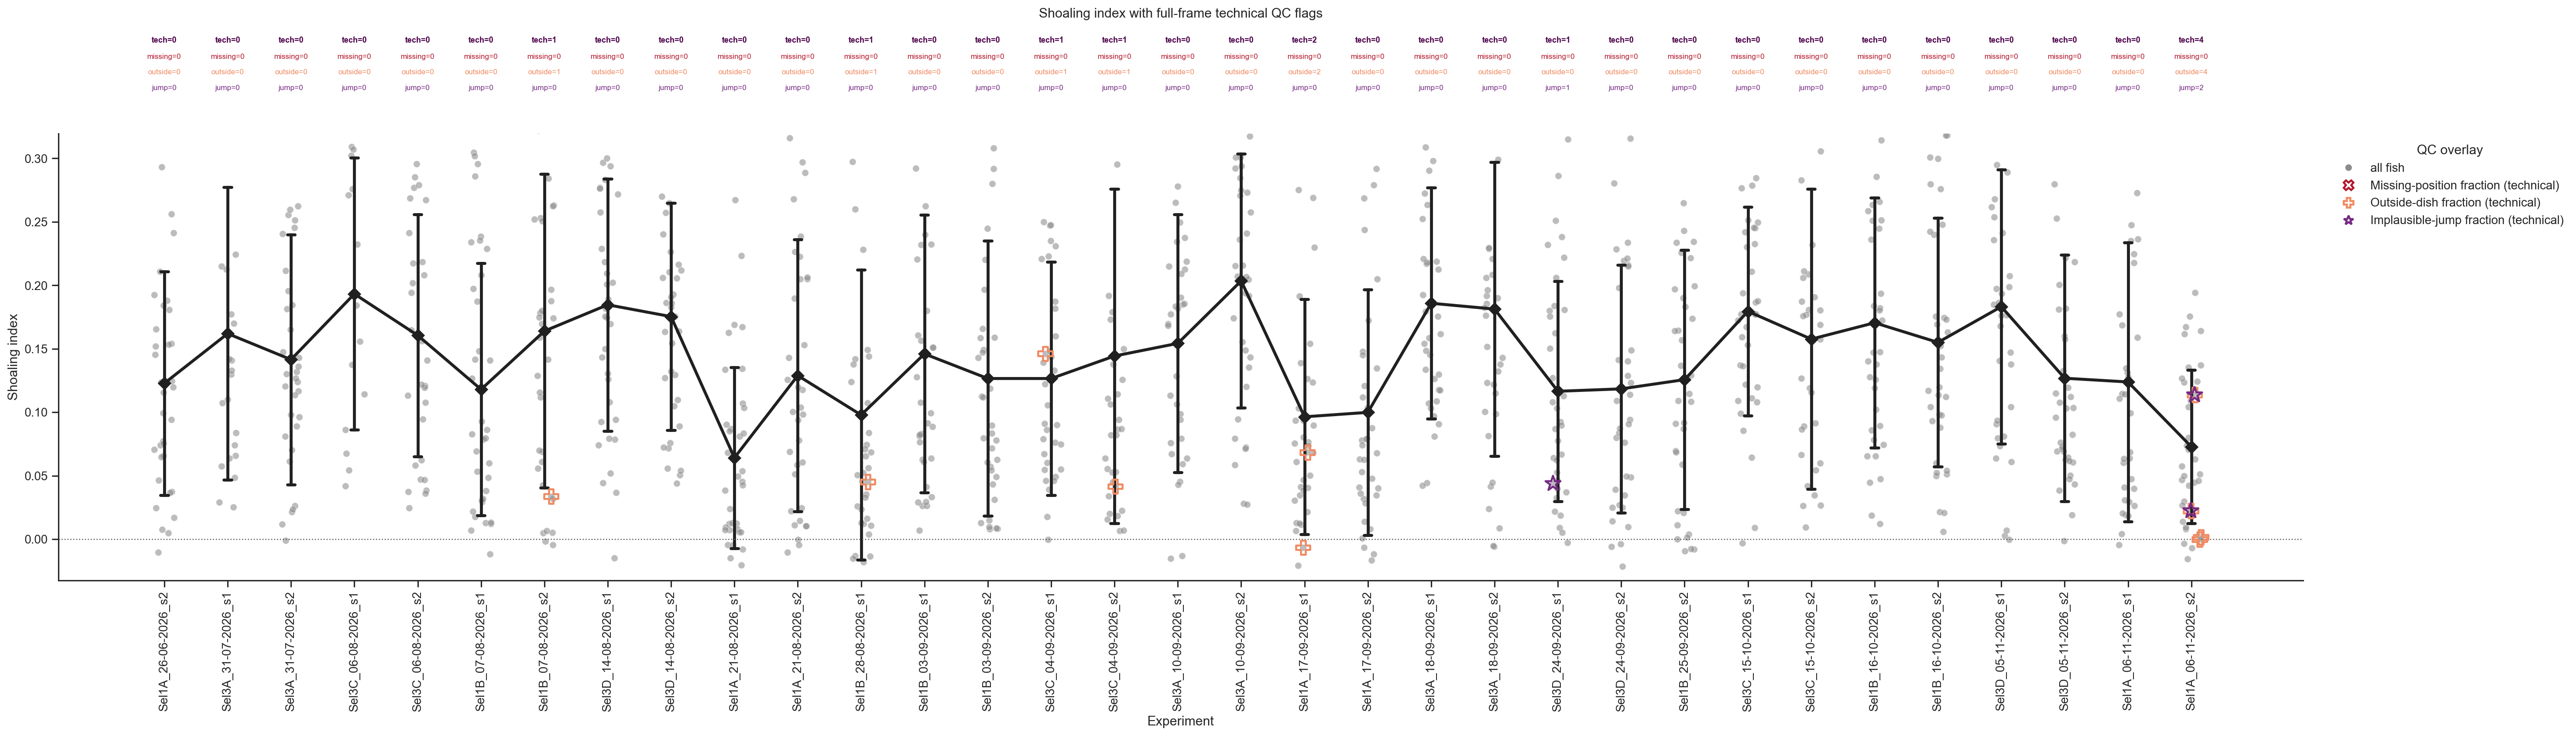

In [6]:
technical_distribution_figure, _ = plot_technical_qc_distributions(
    data=technical_qc_table,
    metric_definitions=TECHNICAL_QC_METRICS,
    threshold=TECHNICAL_QC_FRACTION_THRESHOLD,
    experiment_order=experiment_plot_order,
    add_plot_positions=add_stable_plot_positions,
    summary_color=SUMMARY_COLOR,
    figure_dpi=FIGURE_DPI,
)
save_figure(
    technical_distribution_figure,
    'qtl_technical_qc_metrics_by_experiment',
)

technical_si_figure, _ = plot_si_with_technical_flags(
    data=technical_qc_table,
    technical_metrics=TECHNICAL_QC_METRICS,
    experiment_order=experiment_plot_order,
    add_plot_positions=add_stable_plot_positions,
    unflagged_color=UNFLAGGED_COLOR,
    summary_color=SUMMARY_COLOR,
    figure_dpi=FIGURE_DPI,
    figure_height=FINAL_SI_PLOT_HEIGHT,
    final_si_y_limits=FINAL_SI_Y_LIMITS,
)
save_figure(
    technical_si_figure,
    'qtl_recording_qc_si_by_experiment_with_technical_flags',
)
plt.show()
